<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 3 — Dimensionality Reduction Techniques

**Reference:** John Sukup, *scikit-learn Cookbook*, Third Edition, Chapter 3 (Packt, 2025).

## Learning goals

After working through this notebook, I should be able to:

- explain why high-dimensional data can be difficult to model and visualize;
- distinguish **feature selection** from **feature extraction**;
- apply PCA after scaling and interpret explained variance;
- use LDA when class labels are available and class separation is the goal;
- create a two-dimensional t-SNE view for exploratory visualization;
- compare model performance before and after dimensionality reduction;
- choose a technique based on the task instead of assuming one method is always best.

The examples below follow the topics and learning goals of Chapter 3, but use a freshly structured set of experiments and analyses. Execute the cells from top to bottom.

## 1. Why reduce dimensions?

A feature is one measurable property or input column. A dataset with hundreds of features can be expensive to process and difficult to inspect visually. Some columns may be redundant, noisy, or weakly related to the problem. Dimensionality reduction attempts to represent the data with fewer variables while preserving useful structure.

Two broad approaches are:

- **Feature selection:** keep a subset of original columns. The selected variables retain their original meaning.
- **Feature extraction:** combine or project the original variables into a new, lower-dimensional representation. PCA and LDA are examples.

Reducing dimensions can make a model faster and sometimes improve generalization, but information may be lost. The number of dimensions should therefore be selected using both the task goal and empirical evaluation.

## 2. Set up the libraries and datasets

The Wine dataset is useful for exploring PCA and LDA: it contains numeric chemical measurements and a known class label. The label is kept separate from the feature matrix so that it is not accidentally used by PCA.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_digits, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 2024
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 10)
pd.set_option("display.precision", 3)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.1.3
Pandas: 2.2.3


In [ ]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine = wine.target.copy()

print("Feature matrix shape:", X_wine.shape)
print("Target classes:", list(wine.target_names))
print("Class counts:")
print(y_wine.value_counts().sort_index().rename(index=dict(enumerate(wine.target_names))))
display(X_wine.head())

Feature matrix shape: (178, 13)
Target classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Class counts:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,...,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,...,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,...,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,...,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,...,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,...,1.82,4.32,1.04,2.93,735.0


### Initial observations

The feature matrix contains 178 observations and 13 numeric measurements. Those columns use different units and ranges. For example, a measurement with a large numerical scale could dominate a variance-based method if we applied PCA without considering scaling. Therefore, the later PCA and LDA examples standardize the features first.

In a real project, inspect data types, missing values, feature scales, and the meaning of each feature before choosing a reduction technique.

## 3. Principal Component Analysis (PCA)

PCA is an **unsupervised feature-extraction** technique: it does not use class labels when learning the projection. It creates new axes called principal components. The first component captures the largest possible variance; each later component captures as much remaining variance as possible while being orthogonal to the previous components.

PCA is sensitive to the relative scale of the original features. We therefore place `StandardScaler` and `PCA` in a `Pipeline`. The pipeline keeps the operations together and can later be evaluated safely with cross-validation.

In [ ]:
pca_2d_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=RANDOM_STATE))
])

X_wine_pca_2d = pca_2d_pipeline.fit_transform(X_wine)
pca_2d = pca_2d_pipeline.named_steps["pca"]

print("Original feature matrix:", X_wine.shape)
print("PCA representation:", X_wine_pca_2d.shape)
print(f"Feature count reduced from {X_wine.shape[1]} to {X_wine_pca_2d.shape[1]}")
print(f"Variance retained by first two components: {pca_2d.explained_variance_ratio_.sum():.1%}")

Original feature matrix: (178, 13)
PCA representation: (178, 2)
Feature count reduced from 13 to 2
Variance retained by first two components: 55.4%


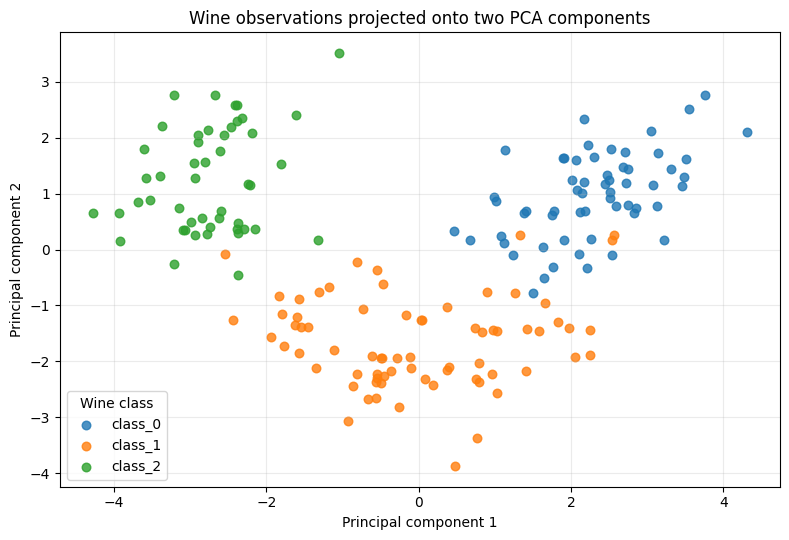

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for class_id, class_name in enumerate(wine.target_names):
    mask = y_wine.to_numpy() == class_id
    ax.scatter(
        X_wine_pca_2d[mask, 0], X_wine_pca_2d[mask, 1],
        s=38, alpha=0.8, label=class_name
    )
ax.set(title="Wine observations projected onto two PCA components",
       xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend(title="Wine class")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Reading the PCA plot

Each dot represents one wine sample, now described by two values instead of 13. If points from different classes occupy different regions, the two-dimensional projection may reveal useful structure. Some overlap is expected because only two components are being viewed and PCA is not trained to separate the known classes.

A visually separated plot is not proof that a predictive model will perform well; model performance needs a separate evaluation.

,Component,Explained variance,Cumulative variance
0,PC1,0.362,0.362
1,PC2,0.192,0.554


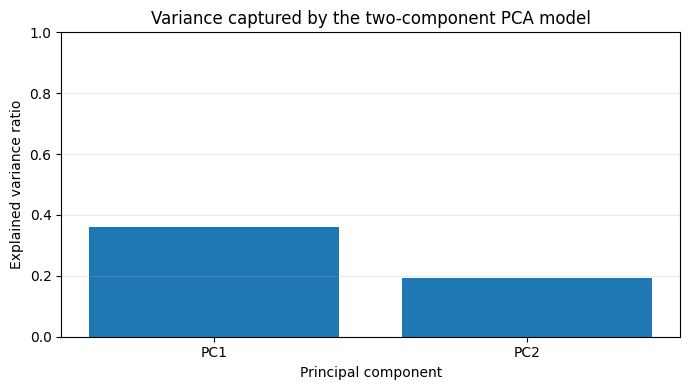

In [ ]:
variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(pca_2d.explained_variance_ratio_) + 1)],
    "Explained variance": pca_2d.explained_variance_ratio_,
    "Cumulative variance": np.cumsum(pca_2d.explained_variance_ratio_)
})
display(variance_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(variance_table["Component"], variance_table["Explained variance"])
ax.set(title="Variance captured by the two-component PCA model",
       xlabel="Principal component", ylabel="Explained variance ratio")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Choosing the number of components

A common approach is to retain enough components to reach a cumulative explained-variance target (for example, 90% or 95%). This is a practical guideline rather than a universal law. A lower threshold produces a smaller representation, while a higher threshold tends to retain more information but may keep more dimensions.

Number of components needed for at least 90% variance: 8
Cumulative variance at that count: 92.0%


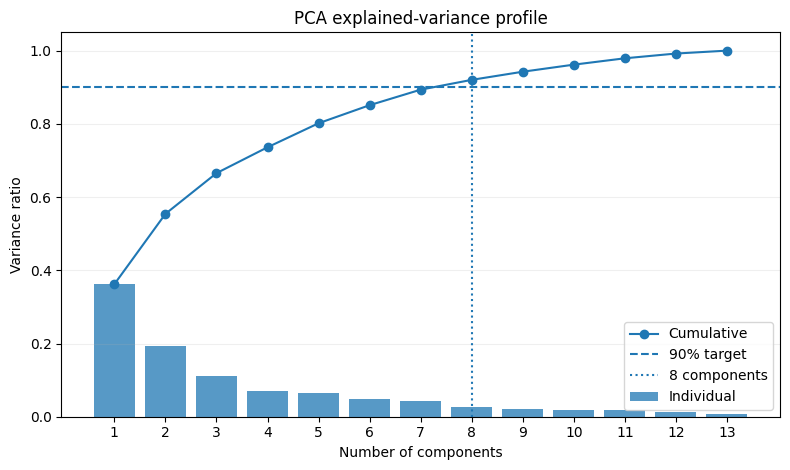

In [ ]:
# Fit PCA with all available components to inspect the full variance curve.
pca_full_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA())
])
pca_full_pipeline.fit(X_wine)
full_pca = pca_full_pipeline.named_steps["pca"]
cumulative = np.cumsum(full_pca.explained_variance_ratio_)

# Find the smallest component count that reaches 90% cumulative variance.
components_for_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print("Number of components needed for at least 90% variance:", components_for_90)
print(f"Cumulative variance at that count: {cumulative[components_for_90 - 1]:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.8))
component_numbers = np.arange(1, len(cumulative) + 1)
ax.bar(component_numbers, full_pca.explained_variance_ratio_, alpha=0.75, label="Individual")
ax.plot(component_numbers, cumulative, marker="o", label="Cumulative")
ax.axhline(0.90, linestyle="--", label="90% target")
ax.axvline(components_for_90, linestyle=":", label=f"{components_for_90} components")
ax.set(title="PCA explained-variance profile", xlabel="Number of components",
       ylabel="Variance ratio", xticks=component_numbers)
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### What do the components combine?

The rows of `components_` show the weights that form each principal component from the standardized original variables. A large absolute weight indicates that a feature contributes more strongly to that component, but the sign indicates direction relative to the other features rather than importance by itself.

In [ ]:
pca_weights = pd.DataFrame(
    pca_2d.components_.T,
    index=X_wine.columns,
    columns=["PC1 weight", "PC2 weight"]
)
# Sort by the combined absolute contribution to make the most influential weights easier to inspect.
pca_weights["Combined absolute weight"] = pca_weights.abs().sum(axis=1)
display(pca_weights.sort_values("Combined absolute weight", ascending=False).drop(columns="Combined absolute weight"))

,PC1 weight,PC2 weight
proline,0.287,0.365
alcohol,0.144,0.484
color_intensity,-0.089,0.530
hue,0.297,-0.279
od280/od315_of_diluted_wines,0.376,-0.164
malic_acid,-0.245,0.225
total_phenols,0.395,0.065
magnesium,0.142,0.300
flavanoids,0.423,-0.003
proanthocyanins,0.313,0.039


## 4. Linear Discriminant Analysis (LDA)

LDA is a **supervised** dimensionality-reduction method. Unlike PCA, it uses the target labels to find projections that make classes as distinguishable as possible. The transformation balances between-class separation against variation within each class.

The maximum number of LDA components is limited by `min(number of features, number of classes - 1)`. Since Wine has three classes, at most two discriminant dimensions can be produced.

In [ ]:
lda_projection = Pipeline([
    ("scale", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=2))
])
X_wine_lda = lda_projection.fit_transform(X_wine, y_wine)
lda_model = lda_projection.named_steps["lda"]

print("Original matrix:", X_wine.shape)
print("LDA matrix:", X_wine_lda.shape)
print("LDA explained discrimination ratios:", np.round(lda_model.explained_variance_ratio_, 3))

Original matrix: (178, 13)
LDA matrix: (178, 2)
LDA explained discrimination ratios: [0.687 0.313]


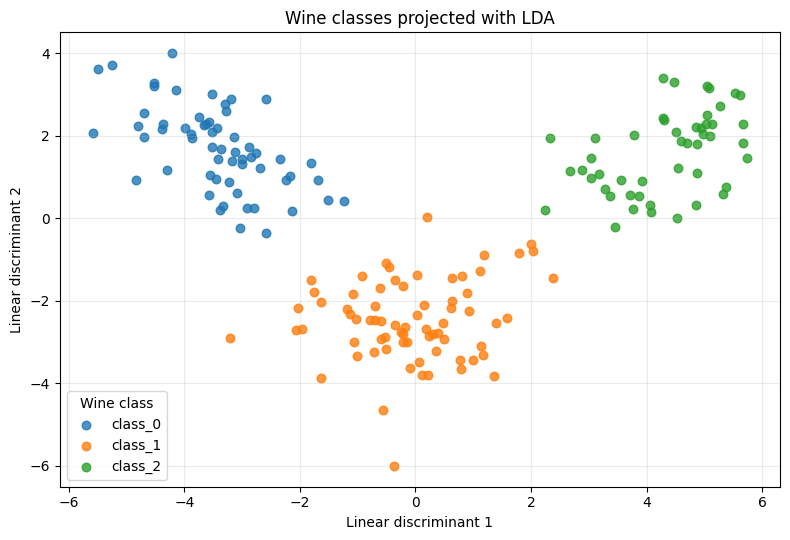

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for class_id, class_name in enumerate(wine.target_names):
    mask = y_wine.to_numpy() == class_id
    ax.scatter(X_wine_lda[mask, 0], X_wine_lda[mask, 1],
               s=38, alpha=0.8, label=class_name)
ax.set(title="Wine classes projected with LDA",
       xlabel="Linear discriminant 1", ylabel="Linear discriminant 2")
ax.legend(title="Wine class")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Comparing PCA and LDA

- **PCA** looks for directions with high overall variance and does not need class labels.
- **LDA** uses class labels and looks for directions that help distinguish those classes.

LDA may show cleaner separation when class information is meaningful, but it is not the appropriate choice when labels are unavailable. The two plots also answer different questions: a PCA plot highlights dominant data variation, while an LDA plot highlights class separability.

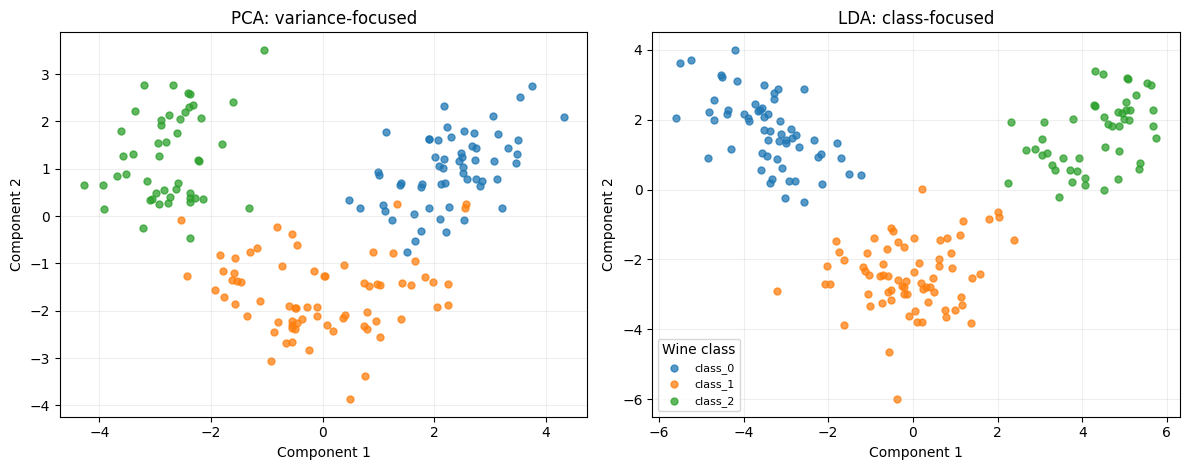

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
views = [(X_wine_pca_2d, "PCA: variance-focused"), (X_wine_lda, "LDA: class-focused")]
for ax, (embedded, title) in zip(axes, views):
    for class_id, class_name in enumerate(wine.target_names):
        mask = y_wine.to_numpy() == class_id
        ax.scatter(embedded[mask, 0], embedded[mask, 1], s=25, alpha=0.75, label=class_name)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.grid(alpha=0.2)
axes[1].legend(title="Wine class", fontsize=8)
plt.tight_layout()
plt.show()

## 5. t-SNE for exploratory visualization

`t-SNE` (t-distributed Stochastic Neighbor Embedding) is a nonlinear technique designed mainly for visualizing high-dimensional samples in two or three dimensions. It attempts to keep nearby observations nearby in the visualization, which can reveal local groupings that are difficult to see in the original feature space.

Important caution: distances between far-apart clusters and the sizes of clusters in a t-SNE plot should not be interpreted as reliable global measurements. The result can change with settings such as perplexity and the random seed. t-SNE is mainly a visualization tool, not a general-purpose replacement for PCA in a predictive pipeline.

Digit data shape: (1797, 64)
Each sample represents an 8 x 8 image, flattened to 64 pixel values.
Label classes: [0 1 2 3 4 5 6 7 8 9]


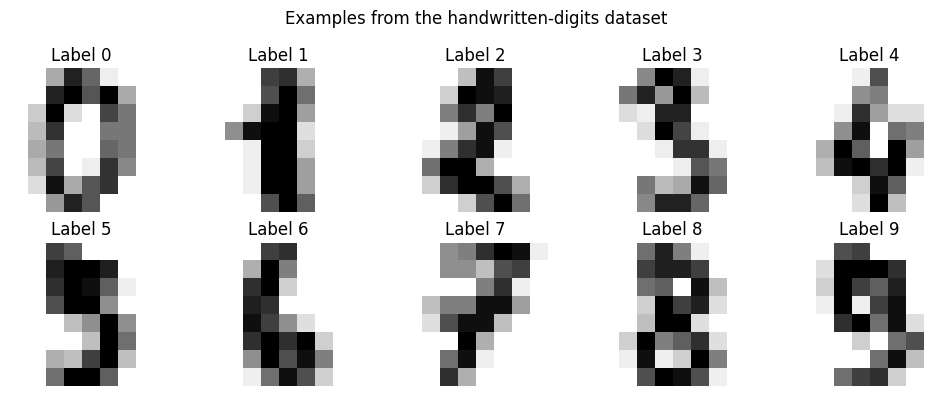

In [ ]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print("Digit data shape:", X_digits.shape)
print("Each sample represents an 8 x 8 image, flattened to 64 pixel values.")
print("Label classes:", np.unique(y_digits))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit_value, ax in enumerate(axes.ravel()):
    image_index = np.flatnonzero(y_digits == digit_value)[0]
    ax.imshow(digits.images[image_index], cmap="gray_r")
    ax.set_title(f"Label {digit_value}")
    ax.axis("off")
plt.suptitle("Examples from the handwritten-digits dataset")
plt.tight_layout()
plt.show()

Scaling can help prevent differences in feature magnitude from dominating distance-based relationships. This notebook applies `StandardScaler` before t-SNE. The data are used for visualization only; the digit labels are used to color the plot after the embedding is created, not as input to t-SNE.

In [ ]:
tsne_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("tsne", TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        init="pca",
        max_iter=750,
        random_state=RANDOM_STATE
    ))
])
X_digits_tsne = tsne_pipeline.fit_transform(X_digits)
print("Embedding shape:", X_digits_tsne.shape)

Embedding shape: (1797, 2)


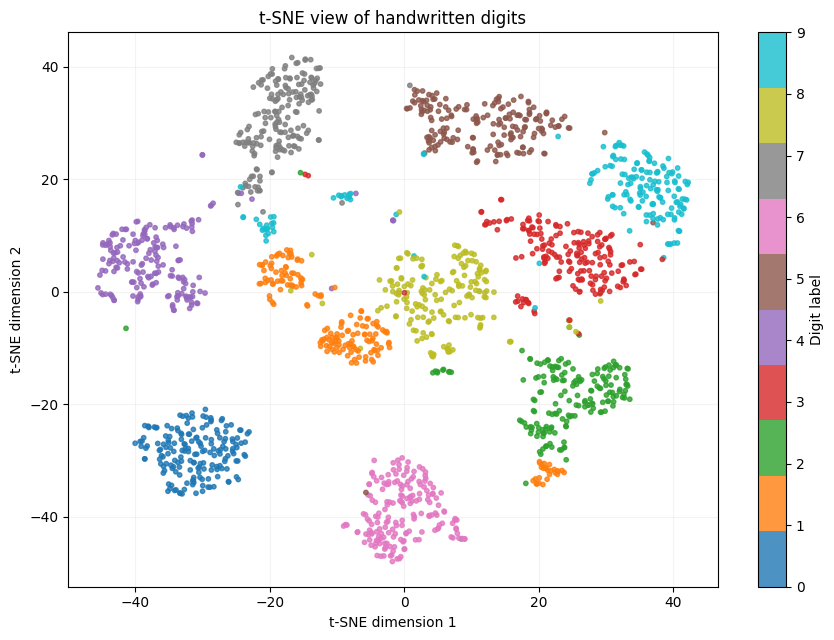

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6.5))
points = ax.scatter(
    X_digits_tsne[:, 0], X_digits_tsne[:, 1],
    c=y_digits, cmap="tab10", s=10, alpha=0.8
)
ax.set(title="t-SNE view of handwritten digits",
       xlabel="t-SNE dimension 1", ylabel="t-SNE dimension 2")
colorbar = fig.colorbar(points, ax=ax, ticks=np.arange(10))
colorbar.set_label("Digit label")
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### Interpreting the t-SNE visualization

Look for groups of points with the same digit label and for labels that overlap. The plot is a visual aid for examining local structure; it does not by itself prove model accuracy or establish a causal relationship. If different runs show different arrangements, that is a reminder to record the settings and random seed when making comparisons.

## 6. Selecting an appropriate technique

| Need or data situation | Possible choice | Reason / caution |
|---|---|---|
| Keep original variable names and remove irrelevant columns | Feature selection | Original features remain interpretable |
| Reduce correlated numeric measurements without labels | PCA | Preserves directions with high variance; usually scale first |
| Improve the separation of known classes in a lower-dimensional space | LDA | Uses labels and is limited by the number of classes |
| Visualize local structure in high-dimensional data | t-SNE | Useful for exploration; not ideal for directly embedding new samples |
| Choose dimensions for a predictive model | Validation experiment | Compare performance within a leakage-safe pipeline |

A practical selection process is to define the goal first, inspect the dataset, try a suitable method, then evaluate either the clarity of the visualization or the model's validation metrics. If the first method is not useful, compare alternatives rather than making an assumption based on the name of the algorithm.

## 7. Impact on a predictive model

Dimensionality reduction can reduce computation and remove redundant variation, but it may discard information relevant to the target. To measure the trade-off, we compare logistic regression on the Iris dataset with: (1) standardized original features, (2) PCA retaining two components, and (3) LDA with two components.

Cross-validation is used here so each preprocessing transformation is learned independently within each training fold. This avoids fitting the scaler or reducer once on the entire dataset before validation.

In [ ]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "All 4 original features": Pipeline([
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "PCA to 2 components": Pipeline([
        ("scale", StandardScaler()),
        ("reduce", PCA(n_components=2, random_state=RANDOM_STATE)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "LDA to 2 components": Pipeline([
        ("scale", StandardScaler()),
        ("reduce", LinearDiscriminantAnalysis(n_components=2)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])
}

results = []
for model_name, model in models.items():
    scores = cross_val_score(model, X_iris, y_iris, cv=cv, scoring="accuracy")
    results.append({
        "Method": model_name,
        "Mean CV accuracy": scores.mean(),
        "Standard deviation": scores.std()
    })
performance = pd.DataFrame(results).sort_values("Mean CV accuracy", ascending=False)
display(performance)

,Method,Mean CV accuracy,Standard deviation
2,LDA to 2 components,0.980,0.027
0,All 4 original features,0.960,0.025
1,PCA to 2 components,0.913,0.034


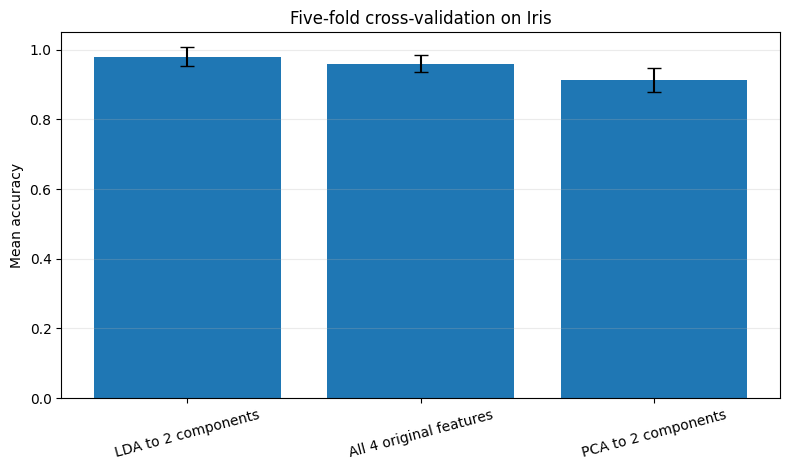

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(performance["Method"], performance["Mean CV accuracy"],
       yerr=performance["Standard deviation"], capsize=5)
ax.set(title="Five-fold cross-validation on Iris",
       ylabel="Mean accuracy", ylim=(0.0, 1.05))
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### How to read this comparison

Use the measured mean and standard deviation rather than expecting a fixed result in advance. If reduced features achieve similar accuracy, the smaller representation may be a reasonable trade-off. If accuracy drops, the discarded information may matter for this task. Small differences should be interpreted cautiously, particularly with a small dataset.

This experiment compares PCA and LDA inside a validation pipeline. t-SNE is not included as a classifier preprocessing option because standard scikit-learn `TSNE` does not provide a general `transform` method for embedding new unseen samples.

## 8. Chapter summary

- Dimensionality reduction can simplify data, lower computation, aid visualization, and sometimes improve generalization, but it can also discard useful signal.
- **PCA** is an unsupervised feature-extraction method that orders orthogonal components by explained variance. Standardization is often necessary when features use different scales.
- **LDA** uses the known labels to search for a lower-dimensional projection that separates classes. Its maximum output dimensions depend on the number of classes.
- **t-SNE** helps explore local structure in high-dimensional data, but its plots should be interpreted cautiously and mainly used for visualization.
- The best method depends on the goal. For predictive use, evaluate dimensionality reduction together with the estimator using cross-validation inside a `Pipeline`.

### Reference

Sukup, John. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Chapter 3, “Dimensionality Reduction Techniques,” printed pages 45–68. The book's companion code repository is available at [PacktPublishing/scikit-learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition).

**Independent practice:** change PCA's component count or t-SNE's `perplexity`, rerun the relevant cells, and record how the visualization, retained variance, or cross-validation metrics change.